# Superstore Sales Analysis
## Business Intelligence & Exploratory Data Analysis

**Project type:** Exploratory Data Analysis (EDA)  
**Dataset:** Sample Superstore  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly

---

## Project Overview

This project explores retail transaction data to evaluate business performance and identify patterns that can support better decisions.

The analysis is organized around five business dimensions:

- **Sales performance:** revenue, order volume, average order value, and time trends.
- **Profitability:** profit, profit margin, loss-making transactions, and discount patterns.
- **Products:** category, sub-category, and product performance.
- **Customers:** customer segments and high-value customers.
- **Operations:** regional performance and shipping efficiency.

### Important data-grain note

Each row represents a product line within an order, not necessarily one complete order. Therefore, order counts must use unique `Order ID` values, while sales and profit are summed across transaction rows.

### Analytical principle

This notebook describes associations and patterns in the available data. It does not assume that one variable causes another.

## 1. Business Questions & Project Objectives

The analysis aims to answer these business questions:

1. How do sales and profit change over time?
2. Which categories and sub-categories contribute most to sales and profit?
3. Which products and business areas generate losses?
4. How are discount levels associated with profitability?
5. Which customer segments and customers contribute most to revenue?
6. Which regions and states perform best?
7. How do shipping methods compare in shipping duration and sales?
8. What practical opportunities can be identified from the results?

**Expected outcome:** A structured business overview supported by measurable results, clear visualizations, and evidence-based recommendations.

## 2. Import Libraries & Configure the Visual Theme

The notebook uses Pandas and NumPy for data work, Matplotlib and Seaborn for statistical charts, and Plotly for interactive exploration.

The visual theme uses a coordinated palette with deep navy, teal, violet, coral, and amber accents. Different chart types are selected according to the question being investigated.

In [26]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, Markdown

# Consistent visual palette
COLORS = {
    "navy": "#172554",
    "blue": "#2563EB",
    "teal": "#0F9D8A",
    "mint": "#8BD3C7",
    "violet": "#7C3AED",
    "coral": "#F97360",
    "amber": "#F4B942",
    "slate": "#64748B",
    "light": "#F1F5F9",
    "dark": "#0F172A"
}

PALETTE = [
    COLORS["blue"], COLORS["teal"], COLORS["violet"],
    COLORS["coral"], COLORS["amber"], COLORS["slate"]
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0,
    rc={
        "axes.facecolor": "#FFFFFF",
        "figure.facecolor": "#FFFFFF",
        "grid.color": "#E2E8F0",
        "grid.linewidth": 0.8,
        "axes.edgecolor": "#CBD5E1",
        "axes.labelcolor": COLORS["dark"],
        "text.color": COLORS["dark"],
        "xtick.color": COLORS["slate"],
        "ytick.color": COLORS["slate"]
    }
)

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlepad"] = 14
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["savefig.facecolor"] = "white"

px.defaults.template = "plotly_white"
px.defaults.color_discrete_sequence = PALETTE

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

## 3. Load the Dataset

Set `file_path` to the location of your dataset. The loader supports both Excel (`.xlsx`, `.xls`) and CSV (`.csv`) files.

For Google Colab, upload the file first or place it in `/content/`. For a local Jupyter Notebook, place it in the notebook folder or provide its full path.

In [27]:
# Update this path if your dataset is stored somewhere else
file_path = "/content/Sample - Superstore.xlsx"

# Read the file based on its extension
file_extension = Path(file_path).suffix.lower()

if file_extension in [".xlsx", ".xls"]:
    df = pd.read_excel(file_path)
elif file_extension == ".csv":
    df = pd.read_csv(file_path, encoding="latin1")
else:
    raise ValueError("Unsupported file format. Use .xlsx, .xls, or .csv.")

# Standardize column labels
df.columns = df.columns.astype(str).str.strip()

# Keep an untouched copy for reference
raw_df = df.copy()

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: 9,994 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-08-11 00:00:00,2016-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.9136
1,2,CA-2016-152156,2016-08-11 00:00:00,2016-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.582
2,3,CA-2016-138688,2016-12-06 00:00:00,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,8714-06-01 00:00:00
3,4,US-2015-108966,2015-11-10 00:00:00,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.031
4,5,US-2015-108966,2015-11-10 00:00:00,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.20,5164-02-01 00:00:00


## 4. Understand the Dataset

Start by reviewing the dataset dimensions, column names, data types, and statistical summaries. This step helps confirm that the loaded file matches the expected structure before any transformation takes place.

In [28]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

display(df.describe(include="all").T)

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,"9,994.00",NaN,NaN,NaN,"4,997.50","2,885.16",1.00,"2,499.25","4,997.50","7,495.75","9,994.00"
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,2016-05-09 00:00:00,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data Dictionary

The standard Sample Superstore dataset contains the following field groups:

| Area | Columns | Description |
|---|---|---|
| Order | `Order ID`, `Order Date`, `Ship Date`, `Ship Mode` | Order reference, order date, shipping date, and delivery method |
| Customer | `Customer ID`, `Customer Name`, `Segment` | Customer identifier, customer name, and segment |
| Geography | `Country`, `City`, `State`, `Postal Code`, `Region` | Geographic information |
| Product | `Product ID`, `Category`, `Sub-Category`, `Product Name` | Product identifiers and classifications |
| Performance | `Sales`, `Quantity`, `Discount`, `Profit` | Transaction value, quantity, discount, and profitability |

The exact fields in the loaded file are confirmed below. If a required field is missing, the notebook stops with a clear message rather than producing misleading results.

In [29]:
required_columns = [
    "Order ID", "Order Date", "Ship Date", "Ship Mode",
    "Customer ID", "Customer Name", "Segment",
    "Region", "State", "Category", "Sub-Category",
    "Product Name", "Sales", "Quantity", "Discount", "Profit"
]

missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(
        "The dataset is missing required columns: " + ", ".join(missing_required)
    )

print("All required analysis columns are available.")

All required analysis columns are available.


## 6. Initial Data Quality Assessment

This section checks missing values, exact duplicate rows, unique values, and the number of unique orders and customers.

Repeated `Order ID` values are expected because one order may contain several product lines. They should not automatically be treated as duplicate records.

In [30]:
quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
}).sort_values("Missing (%)", ascending=False)

display(quality_report)

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Unique orders: {df['Order ID'].nunique():,}")
print(f"Unique customers: {df['Customer ID'].nunique():,}")

,Data Type,Missing Values,Missing (%),Unique Values
Row ID,int64,0,0.00,9994
Order ID,object,0,0.00,5009
Order Date,object,0,0.00,1237
Ship Date,object,0,0.00,1334
Ship Mode,object,0,0.00,4
Customer ID,object,0,0.00,793
Customer Name,object,0,0.00,793
Segment,object,0,0.00,3
Country,object,0,0.00,1
City,object,0,0.00,531


Exact duplicate rows: 0
Unique orders: 5,009
Unique customers: 793


## 7. Data Preparation & Feature Engineering

The preparation stage standardizes date and numeric fields, then creates useful analytical features.

New features:

- `Order Year`: year in which the order was placed.
- `Order Month`: numeric month of the order.
- `Order Month Name`: readable month name.
- `Shipping Days`: elapsed calendar days between order and shipping dates.
- `Profit Margin`: profit as a percentage of sales.
- `Loss Flag`: whether the transaction line has negative profit.

The original loaded data remains available in `raw_df`. Invalid date or numeric values are converted to missing values for safe analysis; they are not silently replaced with invented values.

In [31]:
# Convert date columns
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert numeric columns
numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Create time features
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Month Name"] = df["Order Date"].dt.month_name()
df["Order Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

# Calculate shipping duration
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Create profitability features
df["Profit Margin"] = np.where(
    df["Sales"].notna() & (df["Sales"] != 0) & df["Profit"].notna(),
    df["Profit"] / df["Sales"] * 100,
    np.nan
)
df["Loss Flag"] = df["Profit"] < 0

print("Data preparation completed.")
display(df.head())

Data preparation completed.


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Month Name,Order Year-Month,Shipping Days,Profit Margin,Loss Flag
0,1,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2016,8,August,2016-08,92,16.00,False
1,2,CA-2016-152156,2016-08-11,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2016,8,August,2016-08,92,30.00,False
2,3,CA-2016-138688,2016-12-06,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,NaN,2016,12,December,2016-12,-173,NaN,False
3,4,US-2015-108966,2015-11-10,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03,2015,11,November,2015-11,-23,-40.00,True
4,5,US-2015-108966,2015-11-10,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,NaN,2015,11,November,2015-11,-23,NaN,False


## 8. Data Validation

Validation checks flag suspicious or invalid values for investigation. Negative profit is not automatically invalid: it represents a loss and is a meaningful business outcome. Negative sales, non-positive quantities, discounts outside the expected 0–1 range, and negative shipping duration are highlighted for review.

In [32]:
validation_checks = {
    "Missing Order Dates": int(df["Order Date"].isna().sum()),
    "Missing Ship Dates": int(df["Ship Date"].isna().sum()),
    "Missing Sales": int(df["Sales"].isna().sum()),
    "Missing Profit": int(df["Profit"].isna().sum()),
    "Negative Sales": int(df["Sales"].lt(0).sum()),
    "Non-positive Quantity": int(df["Quantity"].le(0).sum()),
    "Discount Outside 0-1": int(
        (df["Discount"].lt(0) | df["Discount"].gt(1)).sum()
    ),
    "Negative Profit (valid business outcome)": int(df["Profit"].lt(0).sum()),
    "Negative Shipping Days": int(df["Shipping Days"].lt(0).sum())
}

validation_report = pd.DataFrame.from_dict(
    validation_checks, orient="index", columns=["Number of Records"]
)
display(validation_report)

,Number of Records
Missing Order Dates,0
Missing Ship Dates,0
Missing Sales,275
Missing Profit,2279
Negative Sales,0
Non-positive Quantity,0
Discount Outside 0-1,0
Negative Profit (valid business outcome),1871
Negative Shipping Days,1708


## 9. Executive KPI Overview

Key Performance Indicators (KPIs) provide a concise summary of overall business performance.

- **Total Sales:** sum of transaction sales.
- **Total Profit:** sum of transaction profit.
- **Orders:** number of unique orders.
- **Customers:** number of unique customers.
- **Average Order Value (AOV):** average sales value per unique order.
- **Overall Profit Margin:** total profit divided by total sales.
- **Average Discount:** mean transaction discount.

The KPI values are calculated from the loaded dataset and are not hard-coded.

In [33]:
order_totals = df.groupby("Order ID", dropna=True).agg(
    Order_Sales=("Sales", "sum"),
    Order_Profit=("Profit", "sum")
)

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

kpis = {
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Total Orders": df["Order ID"].nunique(),
    "Total Customers": df["Customer ID"].nunique(),
    "Average Order Value": order_totals["Order_Sales"].mean(),
    "Overall Profit Margin (%)": (total_profit / total_sales * 100) if total_sales else np.nan,
    "Average Discount (%)": df["Discount"].mean() * 100
}

kpi_table = pd.DataFrame({
    "KPI": list(kpis.keys()),
    "Value": list(kpis.values())
})
display(kpi_table.style.format({"Value": "{:,.2f}"}))

,KPI,Value
0,Total Sales,"2,233,879.95"
1,Total Profit,"272,832.14"
2,Total Orders,"5,009.00"
3,Total Customers,793.00
4,Average Order Value,445.97
5,Overall Profit Margin (%),12.21
6,Average Discount (%),15.62


## 10. KPI Dashboard

A compact dashboard makes the main business indicators easier to scan before exploring individual questions.

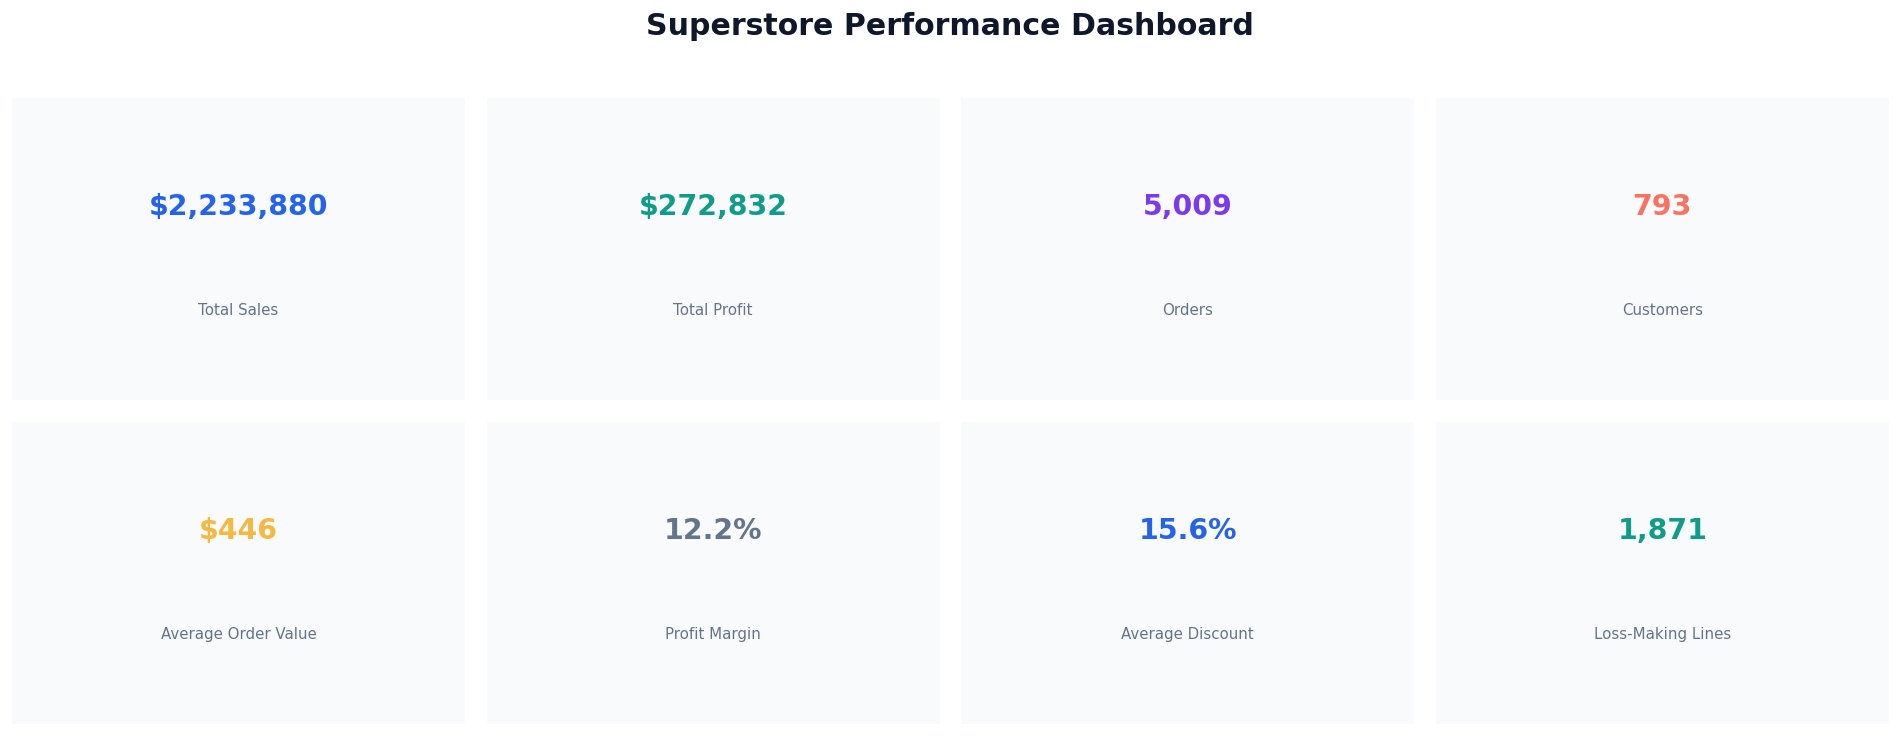

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
axes = axes.flatten()

kpi_items = [
    ("Total Sales", total_sales, "${:,.0f}"),
    ("Total Profit", total_profit, "${:,.0f}"),
    ("Orders", df["Order ID"].nunique(), "{:,.0f}"),
    ("Customers", df["Customer ID"].nunique(), "{:,.0f}"),
    ("Average Order Value", kpis["Average Order Value"], "${:,.0f}"),
    ("Profit Margin", kpis["Overall Profit Margin (%)"], "{:.1f}%"),
    ("Average Discount", kpis["Average Discount (%)"], "{:.1f}%"),
    ("Loss-Making Lines", int(df["Loss Flag"].sum()), "{:,.0f}")
]

for ax, (label, value, fmt), color in zip(axes, kpi_items, PALETTE + PALETTE[:2]):
    ax.set_facecolor("#F8FAFC")
    ax.text(0.5, 0.64, fmt.format(value), ha="center", va="center",
            fontsize=17, fontweight="bold", color=color, transform=ax.transAxes)
    ax.text(0.5, 0.30, label, ha="center", va="center",
            fontsize=9, color=COLORS["slate"], transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("Superstore Performance Dashboard", fontsize=18, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 11. Sales & Profit Distribution

Histograms show how transaction-level sales and profit values are distributed. The distributions can reveal skewness, concentration, and unusually large or small transactions.

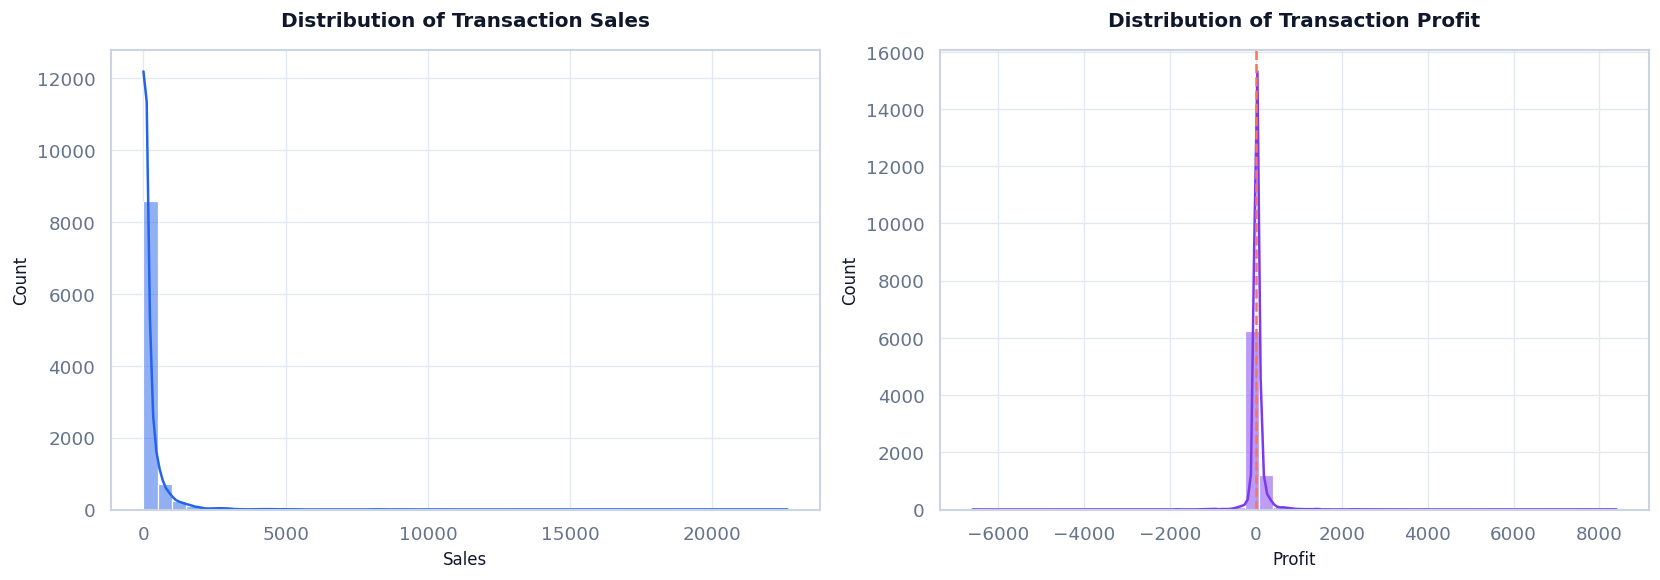

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="Sales", bins=45, kde=True,
    color=COLORS["blue"], ax=axes[0], edgecolor="white"
)
axes[0].set_title("Distribution of Transaction Sales")
axes[0].set_xlabel("Sales")

sns.histplot(
    data=df, x="Profit", bins=45, kde=True,
    color=COLORS["violet"], ax=axes[1], edgecolor="white"
)
axes[1].axvline(0, color=COLORS["coral"], linestyle="--", linewidth=1.5)
axes[1].set_title("Distribution of Transaction Profit")
axes[1].set_xlabel("Profit")

plt.tight_layout()
plt.show()

## 12. Quantity & Discount Patterns

A count plot summarizes the number of transaction lines by quantity. A lollipop-style chart highlights the frequency of each discount level without overcrowding the chart.

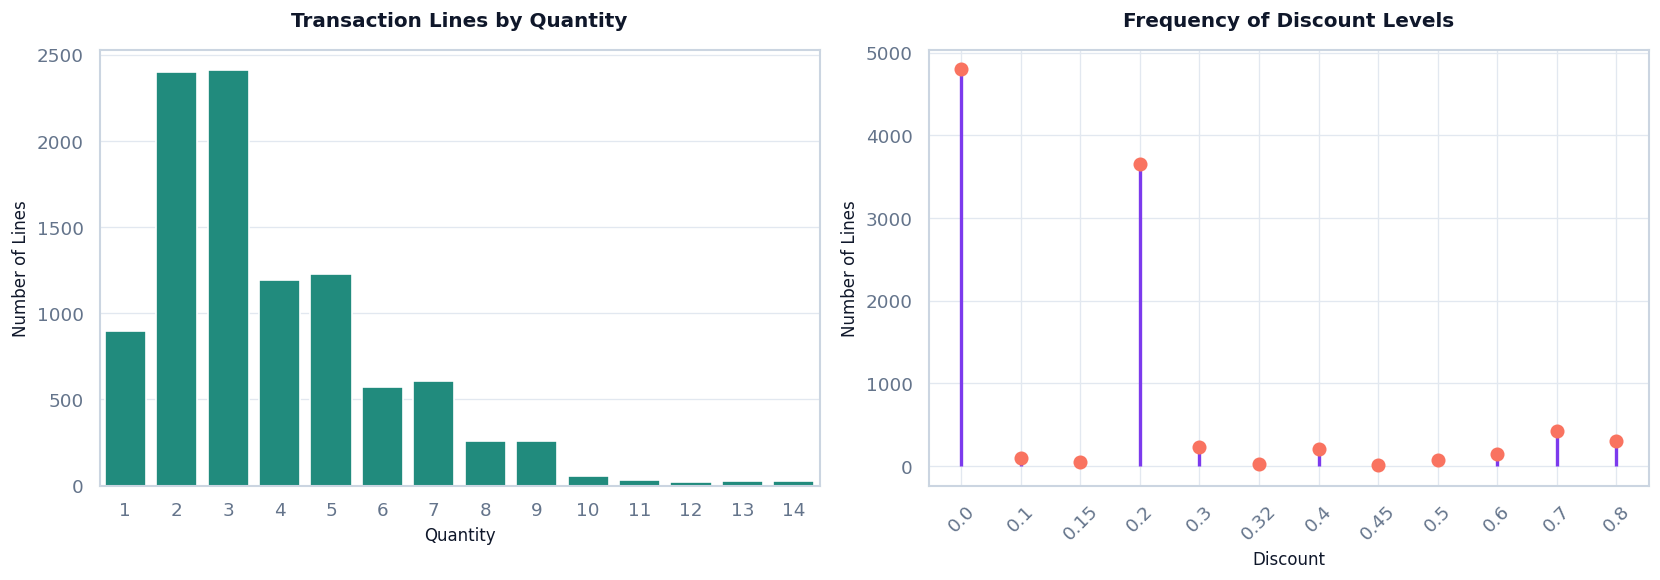

In [11]:
quantity_counts = df["Quantity"].value_counts().sort_index()
discount_counts = df["Discount"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=quantity_counts.index.astype(str),
    y=quantity_counts.values,
    color=COLORS["teal"],
    ax=axes[0]
)
axes[0].set_title("Transaction Lines by Quantity")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Number of Lines")

axes[1].vlines(
    x=discount_counts.index.astype(str),
    ymin=0,
    ymax=discount_counts.values,
    color=COLORS["violet"],
    linewidth=2
)
axes[1].scatter(
    x=discount_counts.index.astype(str),
    y=discount_counts.values,
    color=COLORS["coral"],
    s=55,
    zorder=3
)
axes[1].set_title("Frequency of Discount Levels")
axes[1].set_xlabel("Discount")
axes[1].set_ylabel("Number of Lines")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 13. Monthly Sales Trend

Monthly aggregation helps identify seasonality and changes in demand. The line chart is appropriate because the x-axis represents ordered time periods.

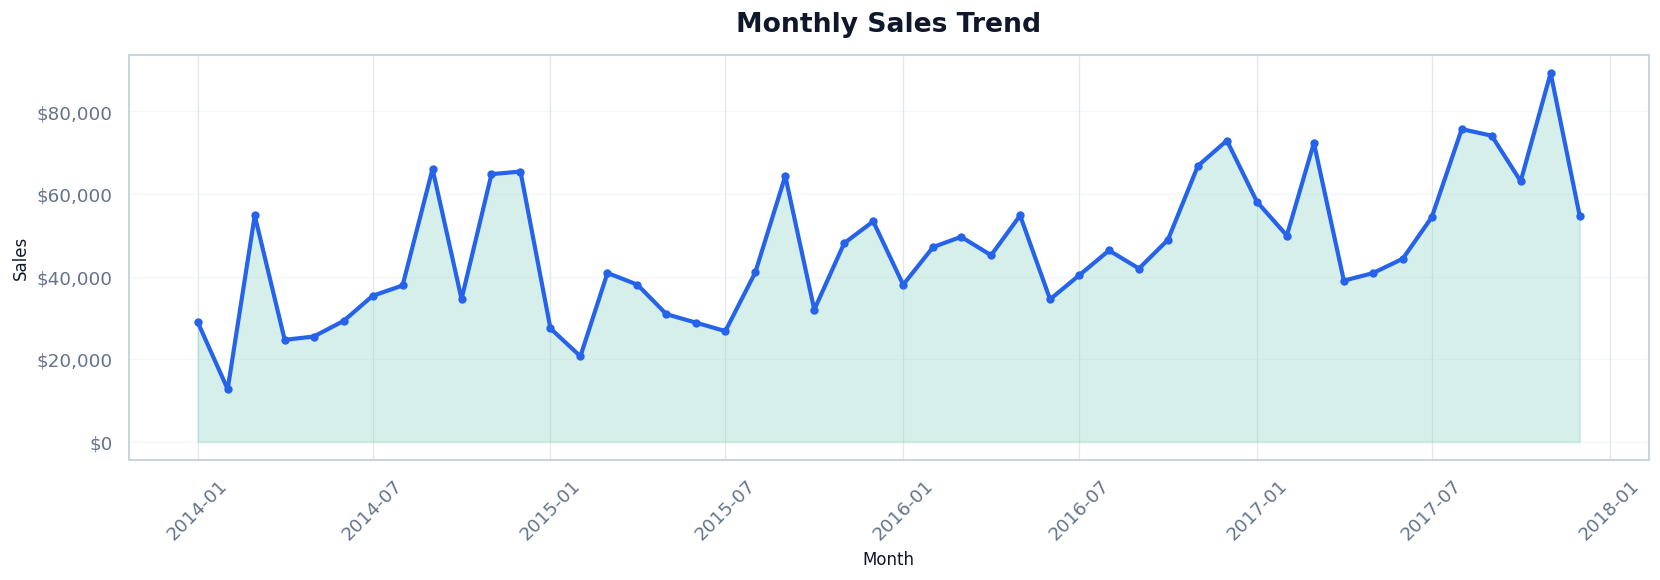

In [12]:
monthly_data = df.dropna(subset=["Order Date", "Sales"]).copy()

monthly_sales = (
    monthly_data.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    monthly_sales.index, monthly_sales.values,
    color=COLORS["blue"], linewidth=2.5, marker="o", markersize=4
)
ax.fill_between(
    monthly_sales.index, monthly_sales.values,
    color=COLORS["mint"], alpha=0.35
)
ax.set_title("Monthly Sales Trend", fontsize=16)
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", alpha=0.35)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 14. Yearly Business Performance

Annual sales and profit are compared using separate panels because sales and profit may have very different magnitudes. This avoids making the profit bars difficult to read.

,Order Year,Sales,Profit,Orders
0,2014,"479,760.66","46,567.14",969
1,2015,"452,209.86","59,018.44",1038
2,2016,"586,250.40","78,343.16",1315
3,2017,"715,659.04","88,903.39",1687


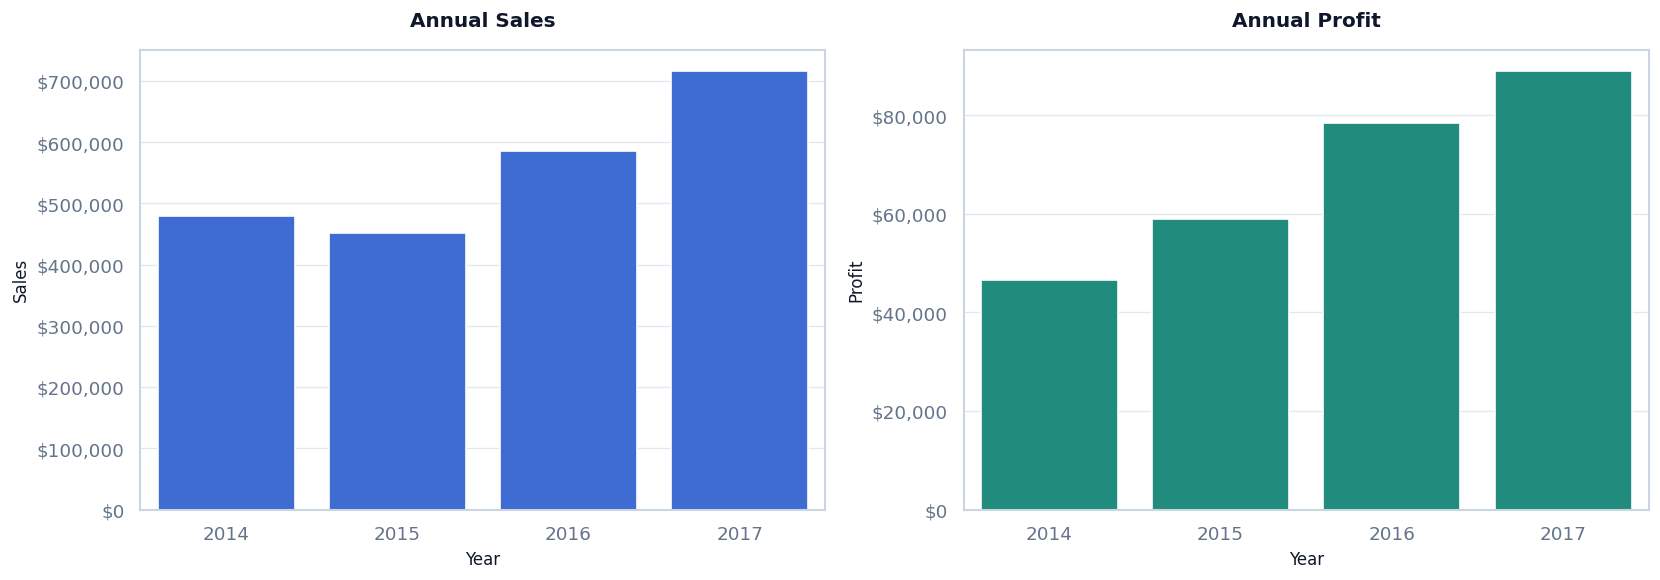

In [13]:
yearly_performance = df.dropna(subset=["Order Year"]).groupby("Order Year").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

display(yearly_performance)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=yearly_performance, x="Order Year", y="Sales",
    color=COLORS["blue"], ax=axes[0]
)
axes[0].set_title("Annual Sales")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

sns.barplot(
    data=yearly_performance, x="Order Year", y="Profit",
    color=COLORS["teal"], ax=axes[1]
)
axes[1].axhline(0, color=COLORS["coral"], linewidth=1)
axes[1].set_title("Annual Profit")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Profit")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

## 15. Category Performance

Category-level results compare sales, profit, and profit margin. High revenue does not necessarily mean high profitability, so both sales and profit are examined.

,Sales,Profit,Quantity,Profit Margin (%)
Category,,,,
Technology,"808,704.62","144,078.30",6939,17.82
Furniture,"723,161.60","16,319.59",8028,2.26
Office Supplies,"702,013.73","112,434.25",22906,16.02


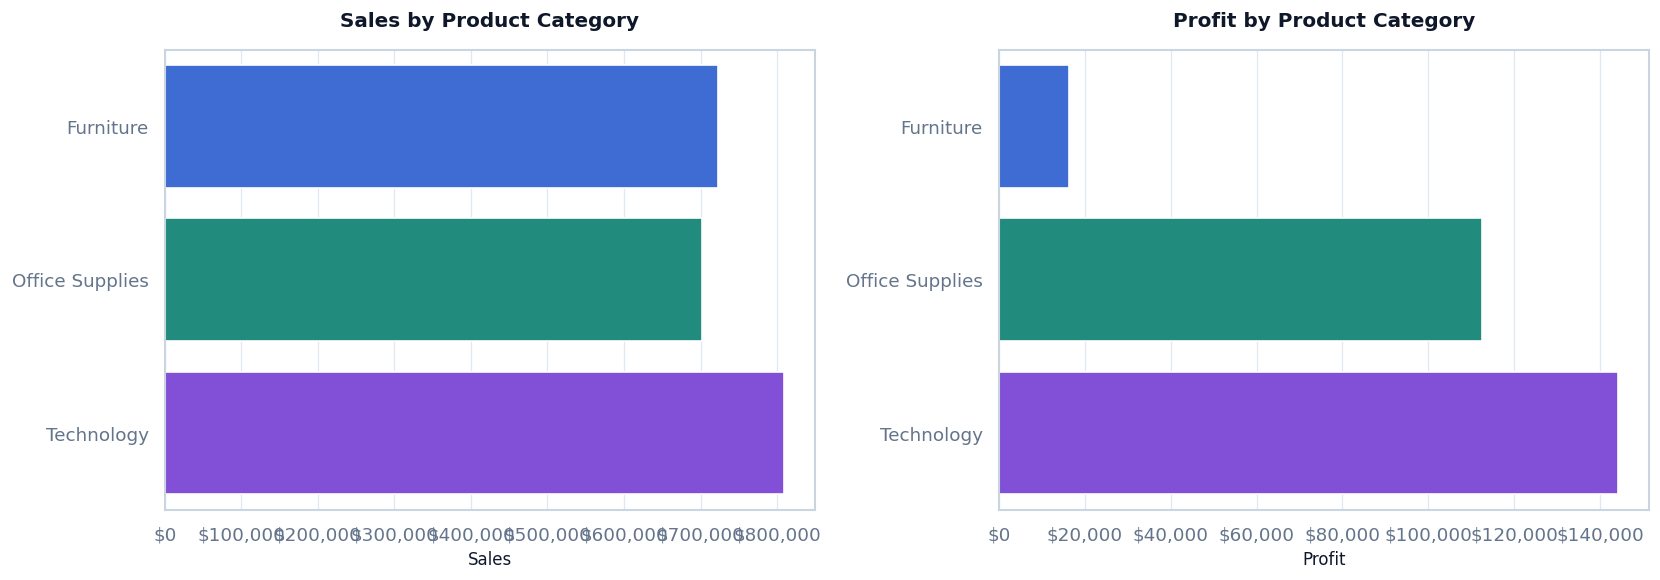

In [14]:
category_performance = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
)
category_performance["Profit Margin (%)"] = (
    category_performance["Profit"] / category_performance["Sales"] * 100
)
display(category_performance.sort_values("Sales", ascending=False))

category_plot = category_performance.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=category_plot, x="Sales", y="Category",
    hue="Category", palette=PALETTE[:3], legend=False, ax=axes[0]
)
axes[0].set_title("Sales by Product Category")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

sns.barplot(
    data=category_plot, x="Profit", y="Category",
    hue="Category", palette=PALETTE[:3], legend=False, ax=axes[1]
)
axes[1].axvline(0, color=COLORS["coral"], linewidth=1)
axes[1].set_title("Profit by Product Category")
axes[1].set_xlabel("Profit")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

## 16. Sub-Category Profitability

Sub-categories are ranked by total profit. A diverging horizontal bar chart makes profitable and loss-making groups easy to distinguish around the zero-profit reference line.

,Sales,Profit,Quantity
Sub-Category,,,
Tables,"200,346.55","-17,828.80",1241
Bookcases,"108,320.20","-3,559.43",868
Supplies,"38,279.57","-1,442.75",647
Fasteners,"2,862.47",527.87,914
Machines,"166,242.43","3,375.76",440
Labels,"12,232.63","4,661.71",1400
Art,"26,683.47","5,102.43",3000
Envelopes,"16,360.78","6,431.12",906
Furnishings,"91,481.68","11,327.20",3563


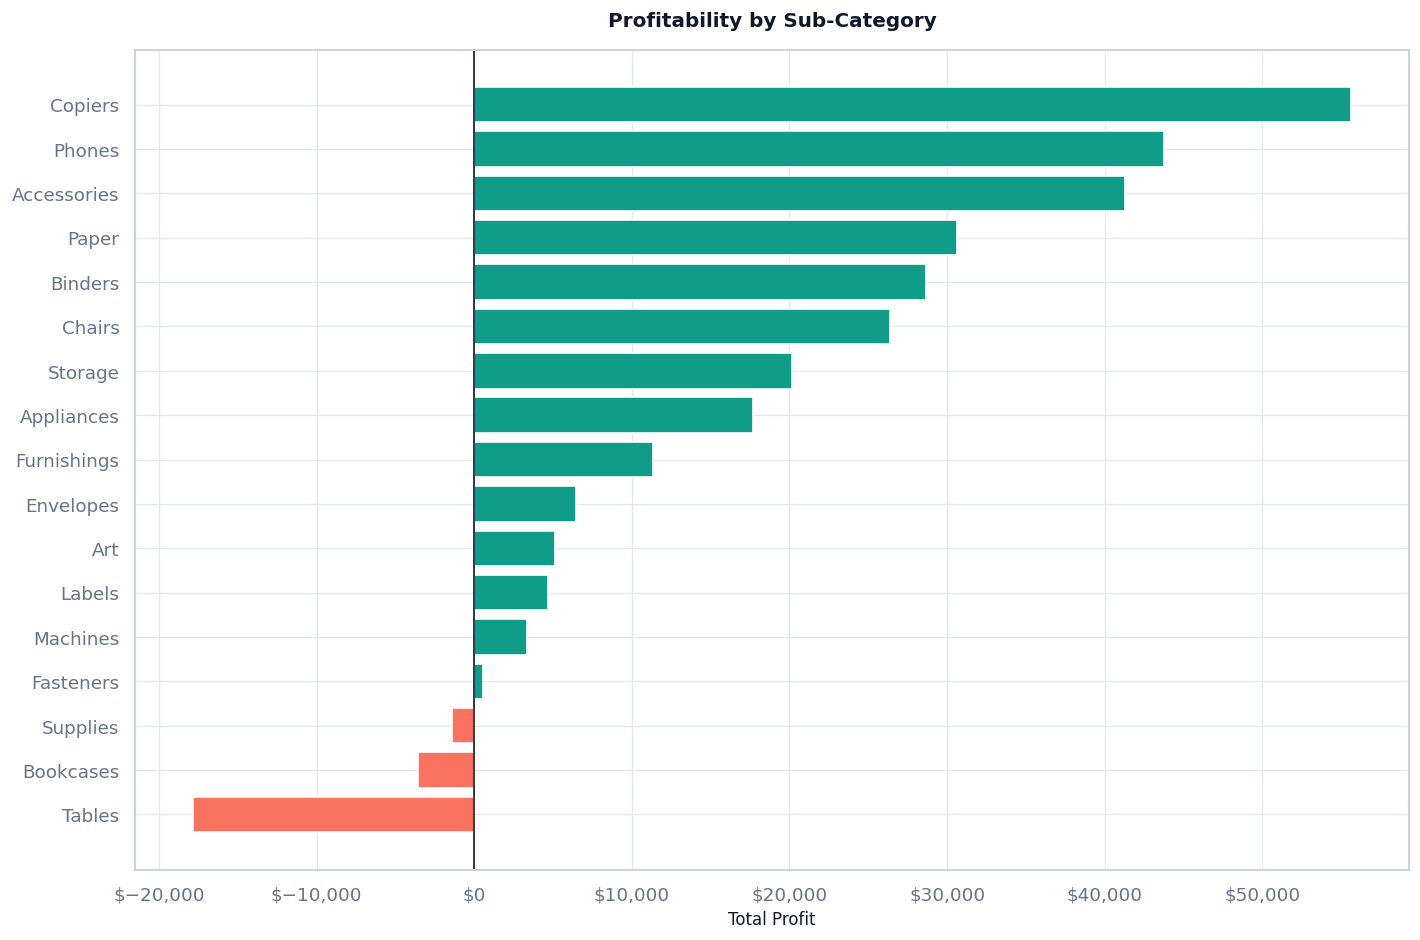

In [15]:
subcat_performance = df.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
).sort_values("Profit")

display(subcat_performance)

subcat_plot = subcat_performance.reset_index()
subcat_colors = [
    COLORS["coral"] if value < 0 else COLORS["teal"]
    for value in subcat_plot["Profit"]
]

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(
    subcat_plot["Sub-Category"],
    subcat_plot["Profit"],
    color=subcat_colors,
    edgecolor="white"
)
ax.axvline(0, color=COLORS["dark"], linewidth=1)
ax.set_title("Profitability by Sub-Category")
ax.set_xlabel("Total Profit")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()
plt.show()

## 17. Product Performance

This section identifies the ten products with the highest sales and the ten products with the lowest total profit. These are different rankings: a product can have high sales and still have weak profitability.

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38","7,753.04",31
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",6
GBC DocuBind TL300 Electric Binding System,"19,823.48","2,233.51",37
GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50",760.98,48
Hewlett Packard LaserJet 3310 Copier,"18,839.69","6,983.88",38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","18,374.90","4,094.98",12
HON 5400 Series Task Chairs for Big and Tall,"18,365.68",0.00,39
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",27


,Sales,Profit,Quantity
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,"11,099.96","-8,879.97",9
Lexmark MX611dhe Monochrome Laser Printer,"16,829.90","-4,589.97",18
Cubify CubeX 3D Printer Triple Head Print,"7,999.98","-3,839.99",4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,"9,917.64","-2,876.12",27
Bush Advantage Collection Racetrack Conference Table,"9,544.73","-1,934.40",33
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",27
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",6
Martin Yale Chadless Opener Electric Letter Opener,"8,328.10","-1,299.18",22
Balt Solid Wood Round Tables,"6,518.75","-1,201.06",19


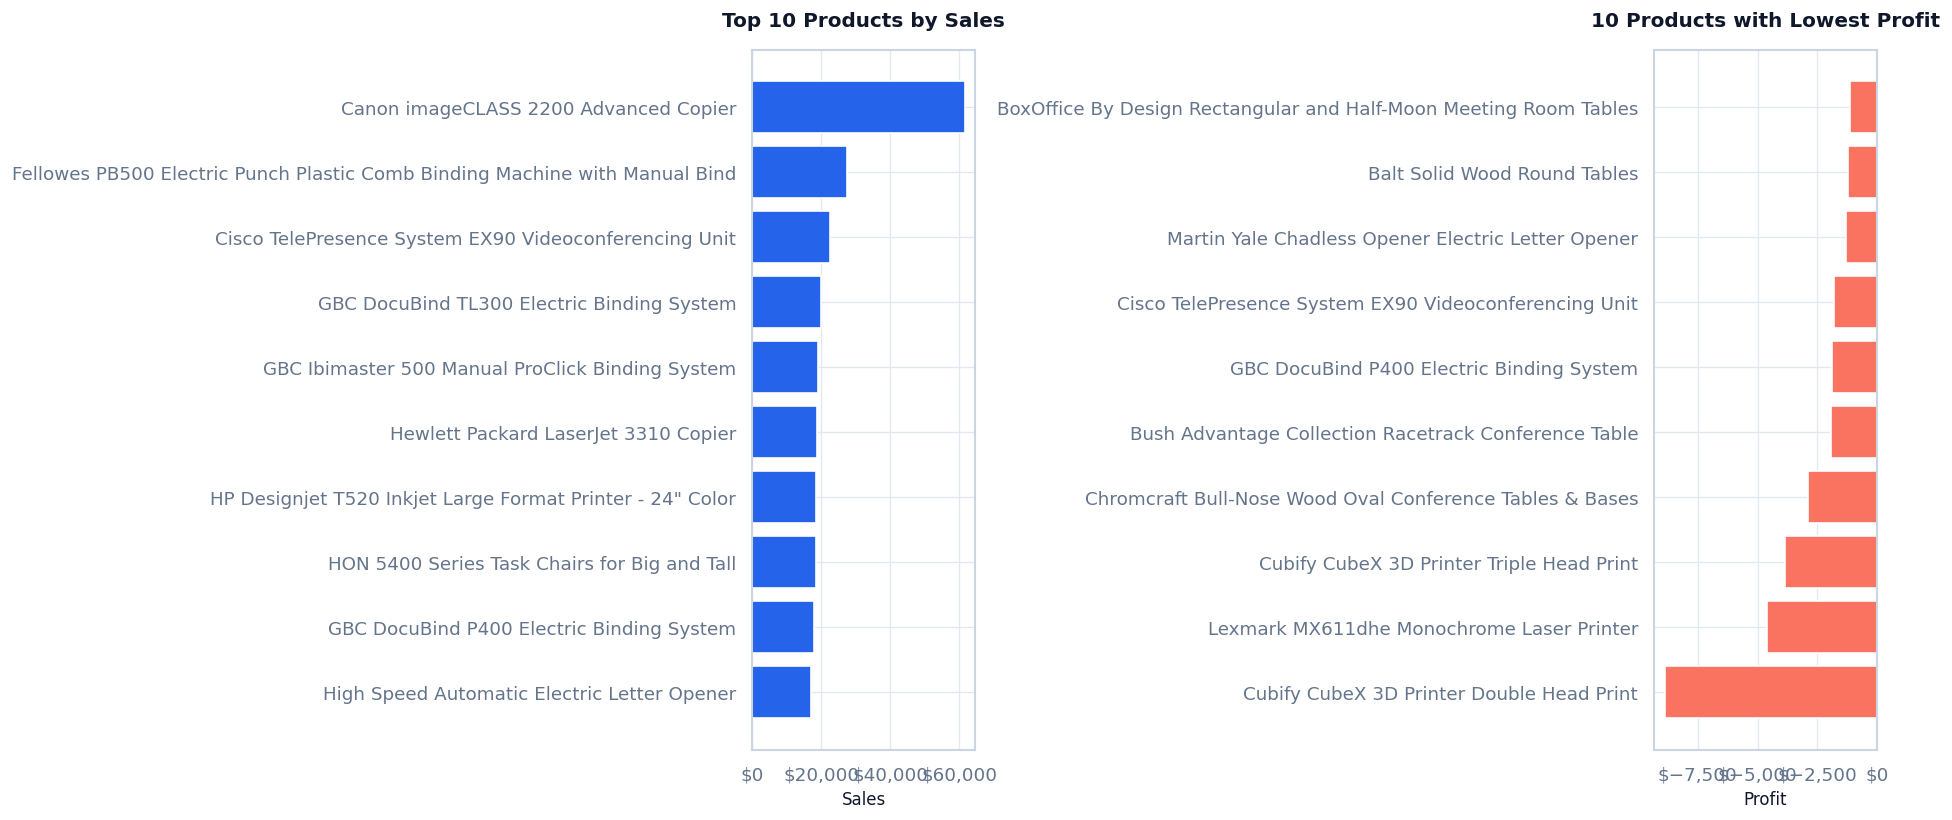

In [16]:
product_performance = df.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
)

top_sales_products = product_performance.nlargest(10, "Sales").sort_values("Sales")
bottom_profit_products = product_performance.nsmallest(10, "Profit").sort_values("Profit")

display(top_sales_products.sort_values("Sales", ascending=False))
display(bottom_profit_products.sort_values("Profit"))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(
    top_sales_products.index, top_sales_products["Sales"],
    color=COLORS["blue"]
)
axes[0].set_title("Top 10 Products by Sales")
axes[0].set_xlabel("Sales")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

axes[1].barh(
    bottom_profit_products.index, bottom_profit_products["Profit"],
    color=COLORS["coral"]
)
axes[1].axvline(0, color=COLORS["dark"], linewidth=1)
axes[1].set_title("10 Products with Lowest Profit")
axes[1].set_xlabel("Profit")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.show()

## 18. Regional & State Performance

Regional aggregation compares total sales, profit, and unique orders. State-level profitability helps locate geographic areas that may need closer investigation.

In [17]:
region_performance = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_values("Sales", ascending=False)

display(region_performance)

fig = px.bar(
    region_performance.reset_index(),
    x="Region", y="Sales",
    color="Region",
    text_auto=".3s",
    title="Sales by Region",
    color_discrete_sequence=PALETTE
)
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Sales")
fig.show()

state_profit = (
    df.groupby("State", as_index=False)["Profit"]
    .sum()
    .sort_values("Profit")
)

fig = px.bar(
    state_profit,
    x="Profit", y="State",
    orientation="h",
    color="Profit",
    color_continuous_scale=["#F97360", "#F8FAFC", "#0F9D8A"],
    title="State-Level Profitability"
)
fig.update_layout(
    xaxis_title="Total Profit",
    yaxis_title="",
    coloraxis_colorbar_title="Profit"
)
fig.show()

,Sales,Profit,Orders
Region,,,
West,"710,246.01","103,454.56",1611
East,"652,225.88","87,642.35",1401
Central,"490,812.67","37,235.94",1175
South,"380,595.39","44,499.29",822


## 19. Customer Segment Analysis

Customer segments are compared using sales, profit, order counts, and customer counts. A donut chart shows the sales contribution of each segment, while a grouped bar chart compares sales and profit.

In [18]:
segment_performance = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")
).reset_index()

display(segment_performance)

fig = px.pie(
    segment_performance,
    names="Segment",
    values="Sales",
    hole=0.58,
    color="Segment",
    color_discrete_sequence=PALETTE,
    title="Sales Contribution by Customer Segment"
)
fig.update_traces(
    textposition="inside",
    textinfo="percent+label",
    marker=dict(line=dict(color="white", width=2))
)
fig.update_layout(showlegend=False)
fig.show()

segment_long = segment_performance.melt(
    id_vars="Segment",
    value_vars=["Sales", "Profit"],
    var_name="Metric",
    value_name="Amount"
)

fig = px.bar(
    segment_long,
    x="Segment", y="Amount",
    color="Metric",
    barmode="group",
    color_discrete_map={"Sales": COLORS["blue"], "Profit": COLORS["coral"]},
    title="Sales and Profit by Customer Segment"
)
fig.show()

,Segment,Sales,Profit,Orders,Customers
0,Consumer,"1,146,778.21","127,037.84",2586,409
1,Corporate,"675,667.72","87,805.84",1514,236
2,Home Office,"411,434.03","57,988.45",909,148


## 20. Customer Value Analysis

Customers are ranked by total sales. The scatter plot compares customer sales and profit, with point size representing the number of unique orders. This reveals whether high-revenue customers also contribute positive profit.

In [19]:
customer_performance = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

top_customers = customer_performance.nlargest(15, "Sales").sort_values("Sales")
display(top_customers.sort_values("Sales", ascending=False))

fig = px.bar(
    top_customers,
    x="Sales", y="Customer Name",
    orientation="h",
    color="Profit",
    color_continuous_scale=["#F97360", "#F8FAFC", "#0F9D8A"],
    hover_data=["Orders", "Profit"],
    title="Top 15 Customers by Sales"
)
fig.show()

fig = px.scatter(
    customer_performance,
    x="Sales", y="Profit",
    size="Orders",
    color="Segment" if "Segment" in customer_performance.columns else None,
    hover_name="Customer Name",
    title="Customer Sales vs. Profit",
    size_max=22,
    opacity=0.75
)
fig.show()

,Customer ID,Customer Name,Sales,Profit,Orders
700,SM-20320,Sean Miller,"25,043.05","-2,005.51",5
741,TC-20980,Tamara Chand,"19,052.22","8,948.67",5
621,RB-19360,Raymond Buch,"15,117.34","6,924.06",6
6,AB-10105,Adrian Barton,"14,473.57","5,420.37",10
434,KL-16645,Ken Lonsdale,"14,175.23",792.13,12
669,SC-20095,Sanjit Chand,"14,124.59","5,738.30",9
327,HL-15040,Hunter Lopez,"12,873.30","5,586.36",6
683,SE-20110,Sanjit Engle,"12,209.44","2,621.61",11
730,TA-21385,Tom Ashbrook,"12,188.98","4,690.81",4
131,CC-12370,Christopher Conant,"12,129.07","2,173.42",5


## 21. Discount & Profit Relationship

The scatter plot investigates the association between discount and profit at transaction-line level. Point size represents sales value. A grouped summary compares average profit and total sales across discount levels.

**Interpretation caution:** An observed relationship does not prove that discounts alone caused a change in profit. Product mix, customer behavior, and other factors may also matter.

In [20]:
scatter_data = df.dropna(
    subset=["Discount", "Profit", "Sales", "Category", "Product Name"]
).copy()

scatter_data = scatter_data[scatter_data["Sales"] > 0]

fig = px.scatter(
    scatter_data,
    x="Discount", y="Profit",
    size="Sales",
    color="Category",
    hover_data=["Product Name", "Sales"],
    size_max=24,
    opacity=0.65,
    title="Discount vs. Profit by Product Category"
)
fig.update_layout(
    xaxis_title="Discount Rate",
    yaxis_title="Profit",
    legend_title="Category"
)
fig.show()

discount_summary = df.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Sales=("Sales", "sum"),
    Transaction_Lines=("Order ID", "size")
).reset_index()

display(discount_summary)

fig = px.bar(
    discount_summary,
    x="Discount", y="Average_Profit",
    color="Average_Profit",
    color_continuous_scale=["#F97360", "#F8FAFC", "#0F9D8A"],
    title="Average Profit by Discount Level",
    text_auto=".2f"
)
fig.add_hline(y=0, line_dash="dash", line_color=COLORS["dark"])
fig.show()

,Discount,Average_Profit,Total_Sales,Transaction_Lines
0,0.00,87.36,"1,039,508.01",4798
1,0.10,108.10,"52,438.31",94
2,0.15,28.94,"27,558.52",52
3,0.20,32.43,"751,749.57",3657
4,0.30,-45.92,"103,226.65",227
5,0.32,-88.56,"14,493.46",27
6,0.40,-114.27,"116,417.78",206
7,0.45,-226.65,"5,484.97",11
8,0.50,-310.70,"58,918.54",66
9,0.60,-43.08,"6,644.70",138


## 22. Shipping Performance

Shipping duration is calculated as the difference between `Ship Date` and `Order Date`.

The summary compares sales, unique orders, average shipping days, and median shipping days for each shipping method. A box plot shows the spread of delivery durations and potential outliers.

In [21]:
shipping_performance = df.groupby("Ship Mode").agg(
    Sales=("Sales", "sum"),
    Orders=("Order ID", "nunique"),
    Average_Shipping_Days=("Shipping Days", "mean"),
    Median_Shipping_Days=("Shipping Days", "median")
).sort_values("Orders", ascending=False)

display(shipping_performance)

shipping_plot = df.dropna(subset=["Ship Mode", "Shipping Days"]).copy()

fig = px.box(
    shipping_plot,
    x="Ship Mode", y="Shipping Days",
    color="Ship Mode",
    color_discrete_sequence=PALETTE,
    points="outliers",
    title="Shipping Duration by Shipping Method"
)
fig.update_layout(
    showlegend=False,
    xaxis_title="Shipping Method",
    yaxis_title="Shipping Days"
)
fig.show()

,Sales,Orders,Average_Shipping_Days,Median_Shipping_Days
Ship Mode,,,,
Standard Class,"1,333,622.83",2994,12.18,5.00
Second Class,"433,625.90",964,5.19,4.00
First Class,"345,409.65",787,6.72,3.00
Same Day,"121,221.57",264,0.56,0.00


## 23. Product Category Mix Across Regions

A stacked bar chart compares each region's sales composition across product categories. This highlights both total regional sales and the category mix within each region.

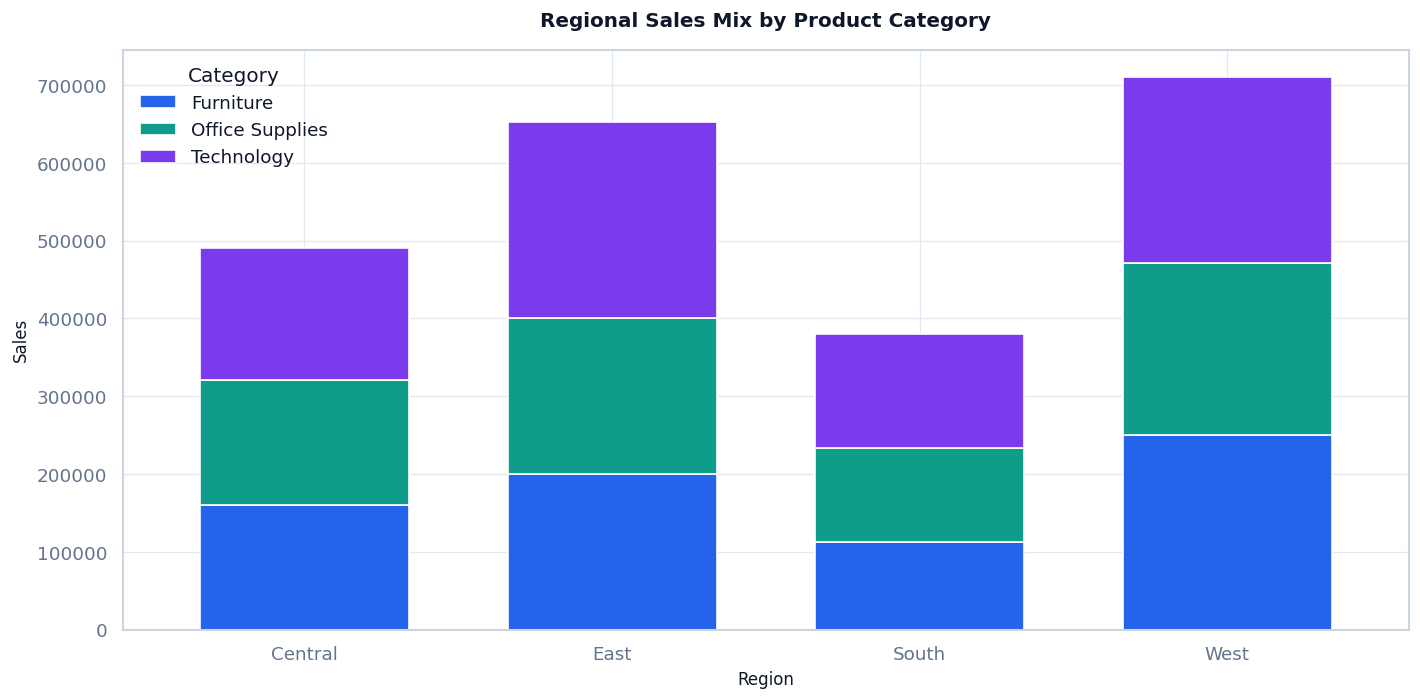

In [22]:
region_category = df.pivot_table(
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

region_category.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=PALETTE[:len(region_category.columns)],
    width=0.68,
    edgecolor="white"
)
plt.title("Regional Sales Mix by Product Category")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.legend(title="Category", frameon=False)
plt.tight_layout()
plt.show()

## 24. Correlation Analysis

Correlation measures the strength and direction of linear association between numeric variables. The heatmap summarizes these relationships.

A correlation value near +1 indicates a strong positive linear relationship; a value near -1 indicates a strong negative linear relationship; a value near 0 indicates a weak linear relationship.

**Correlation does not imply causation.**

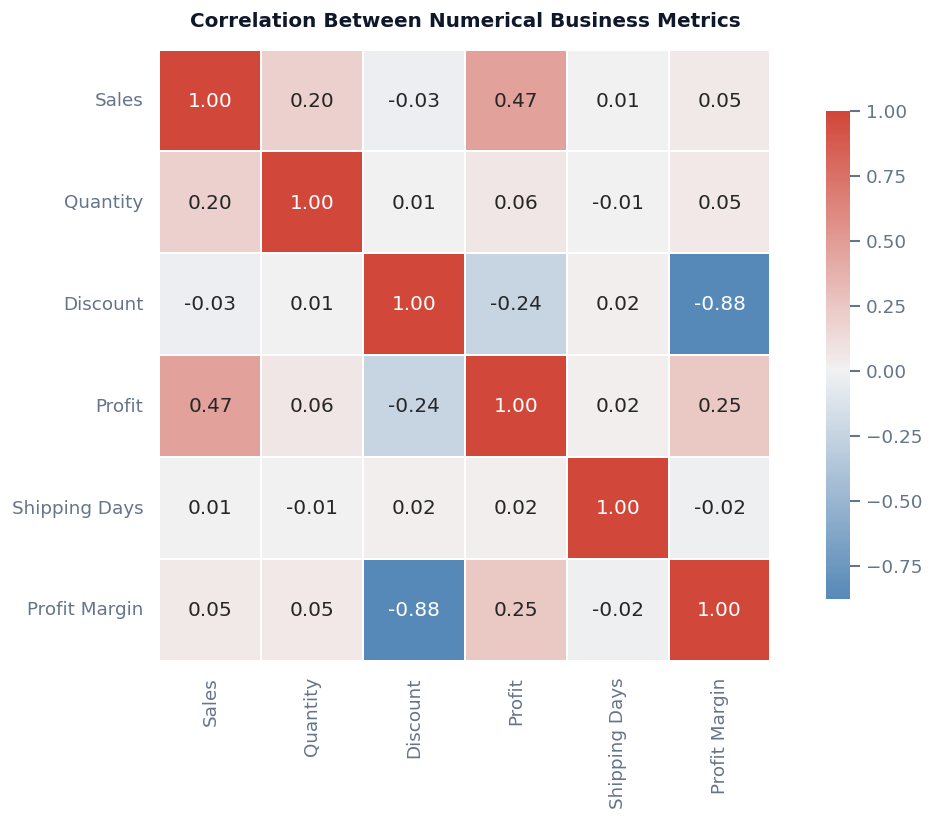

In [23]:
numeric_features = [
    "Sales", "Quantity", "Discount", "Profit",
    "Shipping Days", "Profit Margin"
]

correlation_matrix = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap=sns.diverging_palette(245, 15, as_cmap=True),
    center=0,
    linewidths=1,
    linecolor="white",
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Between Numerical Business Metrics")
plt.tight_layout()
plt.show()

## 25. Interactive Transaction-Level Exploration

This interactive scatter plot allows exploration of sales and profit by category and region. The sample is limited to at most 3,000 valid rows to keep the chart responsive. Sampling affects only this visualization, not the underlying analysis.

In [24]:
plot_sample = df.dropna(
    subset=["Sales", "Profit", "Quantity", "Category", "Region", "Product Name"]
).copy()

plot_sample = plot_sample[
    (plot_sample["Sales"] > 0) &
    (plot_sample["Quantity"] > 0)
]

plot_sample = plot_sample.sample(
    n=min(3000, len(plot_sample)),
    random_state=42
)

fig = px.scatter(
    plot_sample,
    x="Sales", y="Profit",
    color="Category",
    symbol="Region",
    size="Quantity",
    hover_name="Product Name",
    hover_data=["Order ID", "Segment", "Discount"],
    size_max=18,
    opacity=0.7,
    title="Interactive Transaction-Level Sales and Profit"
)
fig.show()

## 26. Business Questions — Data-Driven Answers

The following outputs calculate answers directly from the loaded dataset. Review the results and use them to write concise business interpretations in the final report.

In [25]:
# Q1. Which year generated the highest sales?
best_sales_year = yearly_performance.loc[yearly_performance["Sales"].idxmax()]

# Q2. Which category generated the highest sales?
best_sales_category = category_performance["Sales"].idxmax()

# Q3. Which category generated the highest profit?
best_profit_category = category_performance["Profit"].idxmax()

# Q4. Which sub-category generated the lowest profit?
lowest_profit_subcategory = subcat_performance["Profit"].idxmin()

# Q5. Which region generated the highest sales?
best_sales_region = region_performance["Sales"].idxmax()

# Q6. Which region generated the highest profit?
best_profit_region = region_performance["Profit"].idxmax()

# Q7. Which customer segment generated the highest sales?
best_segment = segment_performance.loc[segment_performance["Sales"].idxmax()]

# Q8. Which shipping method has the shortest median shipping duration?
shipping_median = shipping_performance["Median_Shipping_Days"].dropna()
fastest_shipping_method = shipping_median.idxmin() if not shipping_median.empty else "Not available"

# Q9. How many transaction lines recorded a loss?
loss_lines = int(df["Loss Flag"].sum())

# Q10. What is the overall profit margin?
overall_margin = (df["Profit"].sum() / df["Sales"].sum() * 100) if df["Sales"].sum() else np.nan

answers = [
    ("Highest-sales year", f"{int(best_sales_year['Order Year'])} — ${best_sales_year['Sales']:,.2f}"),
    ("Highest-sales category", f"{best_sales_category} — ${category_performance.loc[best_sales_category, 'Sales']:,.2f}"),
    ("Highest-profit category", f"{best_profit_category} — ${category_performance.loc[best_profit_category, 'Profit']:,.2f}"),
    ("Lowest-profit sub-category", f"{lowest_profit_subcategory} — ${subcat_performance.loc[lowest_profit_subcategory, 'Profit']:,.2f}"),
    ("Highest-sales region", f"{best_sales_region} — ${region_performance.loc[best_sales_region, 'Sales']:,.2f}"),
    ("Highest-profit region", f"{best_profit_region} — ${region_performance.loc[best_profit_region, 'Profit']:,.2f}"),
    ("Highest-sales customer segment", f"{best_segment['Segment']} — ${best_segment['Sales']:,.2f}"),
    ("Shortest median shipping duration", str(fastest_shipping_method)),
    ("Loss-making transaction lines", f"{loss_lines:,}"),
    ("Overall profit margin", f"{overall_margin:.2f}%")
]

answers_df = pd.DataFrame(answers, columns=["Business Question", "Calculated Answer"])
display(answers_df)

,Business Question,Calculated Answer
0,Highest-sales year,"2017 — $715,659.04"
1,Highest-sales category,"Technology — $808,704.62"
2,Highest-profit category,"Technology — $144,078.30"
3,Lowest-profit sub-category,"Tables — $-17,828.80"
4,Highest-sales region,"West — $710,246.01"
5,Highest-profit region,"West — $103,454.56"
6,Highest-sales customer segment,"Consumer — $1,146,778.21"
7,Shortest median shipping duration,Same Day
8,Loss-making transaction lines,"1,871"
9,Overall profit margin,12.21%


## 27. Key Findings & Business Interpretation

Use the calculated tables and charts to write findings in business language. A good finding states what happened, gives the supporting metric, and explains why the result may matter.

Suggested structure:

1. **Observation:** What does the chart or table show?
2. **Evidence:** Which value, category, region, or period supports the observation?
3. **Business implication:** Why might the result matter?
4. **Next step:** What should the business investigate?

Do not claim that a discount, shipping method, or customer characteristic caused an outcome unless the dataset and study design support that conclusion.

## 28. Business Recommendations

Recommendations should be connected to the actual findings generated above. Areas worth investigating may include:

1. Review discount policies for products or sub-categories with weak profitability.
2. Investigate recurring losses in low-performing product groups.
3. Study high-performing regions to understand practices that may be transferable.
4. Review shipping performance where delivery durations are consistently longer.
5. Develop customer-retention strategies based on valuable customer groups.
6. Monitor both revenue and profit when evaluating product or customer performance.

These are investigation opportunities. They should be prioritized only after reviewing the calculated results and considering additional business context.

## 29. Project Limitations

- The analysis is limited to the columns and time period available in the supplied dataset.
- The dataset does not provide all possible business context, such as product costs, inventory levels, marketing spend, or customer acquisition cost.
- A negative profit record does not, by itself, explain why a transaction lost money.
- Relationships between discounts, sales, shipping, and profit should not be interpreted as causal effects.
- The analysis describes observed historical data and is not a forecast of future performance.
- Extreme values should be investigated in context rather than removed automatically.

## 30. Conclusion

This project provides a structured overview of Sample Superstore performance across sales, profitability, products, customers, regions, and shipping operations.

The final conclusions should be based on the calculated KPIs, summary tables, and visual evidence. The strongest recommendations are those that connect a measurable result to a practical business question and a realistic next step.

**Final deliverable:** a reproducible EDA notebook that loads the dataset, validates and prepares the data, explores business performance, answers key questions, and communicates evidence-based findings.